In [1]:
import os

import jax
import jax.numpy as jnp

os.environ["CUDA_VISIBLE_DEVICES"] = "3"

HORIZON = 10
INITIAL_STATE = jnp.array([4.0, 3.0])  # position, velocity

In [2]:
import jax.numpy as jnp
from flax import struct

from hcnn.solver import SQPParameters, SQPProblemBase, sqp_solve


@struct.dataclass
class CloverPhi:
    x_ref: jax.Array


phi = CloverPhi(
    x_ref=jnp.array([2.0, 2.0]),
)


@struct.dataclass
class CloverProblem(SQPProblemBase[CloverPhi]):
    ### INITIALIZATION ###
    # get initial guess for optimization variable x (vectorized 1d)
    def get_x0(self, phi: CloverPhi) -> jax.Array:
        return jnp.array([0.0, 0.0])

    @property
    def x0(self):
        return self.get_x0(self.phi)

    ### QUADRATIC COST ###
    # f(x) = 1/2 x.T @ diag(q) @ x + c.T @ x
    cost_quad_diag: jax.Array  # q in cost (vectorized 1d)
    cost_linear: jax.Array  # c in cost (vectorized 1d)

    ### NONLINEAR PARAMETRIC CONSTRAINTS ###
    # l <= h(x, phi) <= u
    def constraint_fn_phi(self, x: jax.Array, phi: CloverPhi) -> jax.Array:
        # x = x_ref + dx
        x1 = phi.x_ref[0] + x[..., 0]
        # y = y_ref + dy
        x2 = phi.x_ref[1] + x[..., 1]
        return jnp.array(
            [x1**4 + 2 * x1**2 * x2**2 + x2**4 - x1**3 + 3 * x1 * x2**2]
        )

    def constraint_fn(self, x: jax.Array) -> jax.Array:
        return self.constraint_fn_phi(x, self.phi)

    phi: CloverPhi
    lower_bound: jax.Array  # l in constraint (vectorized 1d)
    upper_bound: jax.Array  # u in constraint (vectorized 1d)


problem = CloverProblem(
    cost_quad_diag=jnp.array([1.0, 1.0]),
    cost_linear=jnp.array([0.0, 0.0]),
    phi=phi,
    lower_bound=jnp.array([-2.0]),
    upper_bound=jnp.array([1e-3]),
)

parameters = SQPParameters(
    max_iter_nonlin=250,
    max_iter_lin=5_000,
    tol_prim=1e-4,
    tol_dual=1e-4,
    tol_osqp=1e-6,
)

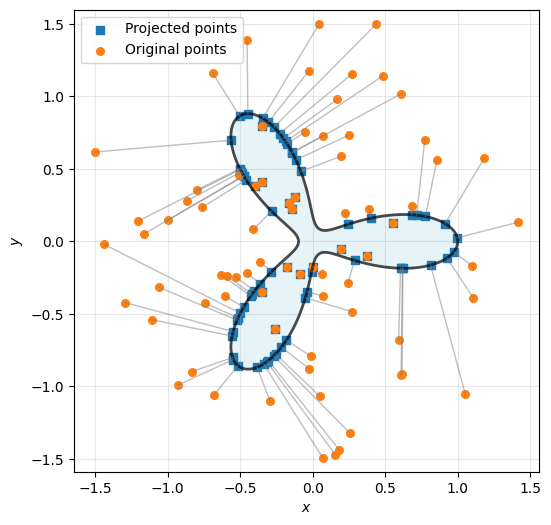

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Configure the plot
plt.figure(figsize=(6, 6))

# Sample random 2D x_ref points from Gaussian distribution
n_samples = 75
np.random.seed(42)  # For reproducibility
# Use Gaussian with std=0.5 to concentrate samples near center -> clip to range
x_ref_samples = np.random.normal(0, 0.75, (n_samples, 2))
x_ref_samples = np.clip(x_ref_samples, -1.5, 1.5)  # Keep within desired range


# Define a function to project a single point (for vmap)
def project_single_point(x_ref_sample):
    # Create a new phi with the sampled x_ref
    phi_sample = CloverPhi(
        x_ref=x_ref_sample,
    )

    # Create problem with the new phi
    problem_sample = CloverProblem(
        cost_quad_diag=problem.cost_quad_diag,
        cost_linear=problem.cost_linear,
        phi=phi_sample,
        lower_bound=problem.lower_bound,
        upper_bound=problem.upper_bound,
    )

    # Solve for projection
    x_proj, _ = sqp_solve(problem_sample, parameters)
    projection_sample = phi_sample.x_ref + x_proj

    return projection_sample


# Use vmap to vectorize the projection operation
project_points_vmap = jax.vmap(project_single_point)

# Convert to JAX arrays and project all points at once
x_ref_samples_jax = jnp.array(x_ref_samples)
projected_points_jax = project_points_vmap(x_ref_samples_jax)

# Convert back to numpy for plotting
original_points = np.array(x_ref_samples)
projected_points = np.array(projected_points_jax)

# Plot the constraint boundary (clover shape)
x_range = np.linspace(-1.2, 1.2, 200)
y_range = np.linspace(-1.2, 1.2, 200)
X, Y = np.meshgrid(x_range, y_range)

# Evaluate constraint function over the grid
phi_grid = CloverPhi(
    x_ref=jnp.array([0.0, 0.0]),
)

# For visualization, we compute the constraint directly
constraint_values = X**4 + 2 * X**2 * Y**2 + Y**4 - X**3 + 3 * X * Y**2

# Plot constraint boundary
plt.contour(
    X,
    Y,
    constraint_values,
    levels=[1e-3],
    colors="black",
    linewidths=2,
    alpha=0.7,
)
plt.contourf(
    X,
    Y,
    constraint_values,
    levels=[-2, 1e-3],
    colors=["lightblue"],
    alpha=0.3,
)

# Plot projected points
plt.scatter(
    projected_points[:, 0],
    projected_points[:, 1],
    c="C0",
    marker="s",
    s=30,
    label="Projected points",
)

# Plot original points
plt.scatter(
    original_points[:, 0],
    original_points[:, 1],
    c="C1",
    marker="o",
    s=30,
    label="Original points",
)

# Draw lines from original to projected points
for i in range(len(original_points)):
    plt.plot(
        [original_points[i, 0], projected_points[i, 0]],
        [original_points[i, 1], projected_points[i, 1]],
        color="gray",
        alpha=0.5,
        linewidth=1,
    )

plt.xlabel(r"$x$")
plt.ylabel(r"$y$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.axis("equal")

# Save as PDF
plt.savefig("clover_projection.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [4]:
# Gradient check for all projected points
def inner_prod(xs, ys):
    """Compute inner product between two pytrees"""

    def contract(x, y):
        return jnp.real(jnp.dot(jnp.conj(x).reshape(-1), y.reshape(-1)))

    return jax.tree_util.tree_reduce(
        jnp.add, jax.tree_util.tree_map(contract, xs, ys)
    )


def numerical_jvp(f, primals, tangents, eps=1e-5):
    """Compute JVP using finite differences: [f(x + ε·v) - f(x - ε·v)] / (2ε)"""

    # Scale tangents by eps
    def scalar_mul(tree, scalar):
        return jax.tree_util.tree_map(lambda x: x * scalar, tree)

    def tree_add(tree1, tree2):
        return jax.tree_util.tree_map(lambda x, y: x + y, tree1, tree2)

    def tree_sub(tree1, tree2):
        return jax.tree_util.tree_map(lambda x, y: x - y, tree1, tree2)

    delta = scalar_mul(tangents, eps)
    f_pos = f(tree_add(primals, delta))
    f_neg = f(tree_sub(primals, delta))
    return scalar_mul(tree_sub(f_pos, f_neg), 0.5 / eps)


def projection_fn(phi_input):
    """Function that takes phi and returns the optimized x"""
    # Create a new problem with the input phi
    temp_problem = CloverProblem(
        cost_quad_diag=problem.cost_quad_diag,
        cost_linear=problem.cost_linear,
        phi=phi_input,
        lower_bound=problem.lower_bound,
        upper_bound=problem.upper_bound,
    )

    # Solve for projection
    x_proj, _ = sqp_solve(temp_problem, parameters)
    return x_proj


# Function to perform gradient check for a single point
def gradient_check_single_point(x_ref_sample):
    # Create phi for this point
    phi_sample = CloverPhi(x_ref=x_ref_sample)

    # Generate random tangent and cotangent vectors
    tangent = jax.tree_util.tree_map(
        lambda x: jax.random.normal(jax.random.key(0), x.shape), phi_sample
    )

    # Solve the projection problem to get x_star
    x_star, solve_info = sqp_solve(
        CloverProblem(
            cost_quad_diag=problem.cost_quad_diag,
            cost_linear=problem.cost_linear,
            phi=phi_sample,
            lower_bound=problem.lower_bound,
            upper_bound=problem.upper_bound,
        ),
        parameters,
    )

    cotangent = jax.tree_util.tree_map(
        lambda x: jax.random.normal(jax.random.key(1), x.shape), x_star
    )

    # Calculate numerical JVP
    eps = 1e-4
    tangent_out = numerical_jvp(projection_fn, phi_sample, tangent, eps=eps)

    # Calculate analytical VJP using JAX's vjp
    _, vjp_fn = jax.vjp(projection_fn, phi_sample)
    cotangent_out = vjp_fn(cotangent)[0]

    # Calculate inner products
    ip_vjp = inner_prod(tangent, cotangent_out)
    ip_jvp = inner_prod(tangent_out, cotangent)
    difference = jnp.abs(ip_vjp - ip_jvp)

    return difference, ip_vjp, ip_jvp


print("Performing gradient check for all projected points...")

Performing gradient check for all projected points...


In [5]:
# Sample random 2D x_ref points from Gaussian distribution
n_samples = int(2e3)  # 2000 points
np.random.seed(42)  # For reproducibility
# Use Gaussian with std=0.5 to concentrate samples near center -> clip to range
x_ref_samples_jax = np.random.normal(0, 0.75, (n_samples, 2))
x_ref_samples_jax = np.clip(
    x_ref_samples_jax, -1.5, 1.5
)  # Keep within desired range

In [6]:
# Run gradient check for all sample points
gradient_check_vmap = jax.vmap(gradient_check_single_point)

# Use the same x_ref samples that were used for projection
differences, ip_vjps, ip_jvps = gradient_check_vmap(x_ref_samples_jax)

# Convert to numpy for statistics
differences_np = np.array(differences)
ip_vjps_np = np.array(ip_vjps)
ip_jvps_np = np.array(ip_jvps)

# Calculate statistics
mean_difference = np.mean(differences_np)
std_difference = np.std(differences_np)
max_difference = np.max(differences_np)
min_difference = np.min(differences_np)

print(f"Gradient Check Results for {n_samples} points:")
print(f"Mean difference: {mean_difference:.6e}")
print(f"Standard deviation: {std_difference:.6e}")
print(f"Maximum difference: {max_difference:.6e}")
print(f"Minimum difference: {min_difference:.6e}")
print(f"Mean VJP inner product: {np.mean(ip_vjps_np):.6f}")
print(f"Mean JVP inner product: {np.mean(ip_jvps_np):.6f}")

# Check if the gradient check passes (typically should be < 1e-5 for accuracy)
tolerance = 1e-4
passed_checks = np.sum(differences_np < tolerance)
print(
    f"\nGradient checks passed (< {tolerance:.0e}): {passed_checks}/{n_samples} ({100 * passed_checks / n_samples:.1f}%)"  # noqa: E501
)

Gradient Check Results for 2000 points:
Mean difference: 3.008111e+04
Standard deviation: 1.344908e+06
Maximum difference: 6.016118e+07
Minimum difference: 0.000000e+00
Mean VJP inner product: 0.038074
Mean JVP inner product: -30080.726562

Gradient checks passed (< 1e-04): 334/2000 (16.7%)


In [7]:
# Filter out outliers using percentile method (exclude upper 2%)
percentile_threshold = 98  # Keep bottom 98% of data
threshold_value = np.percentile(differences_np, percentile_threshold)
outlier_mask = differences_np <= threshold_value

# Filter all arrays
differences_filtered = differences_np[outlier_mask]
ip_vjps_filtered = ip_vjps_np[outlier_mask]
ip_jvps_filtered = ip_jvps_np[outlier_mask]
x_ref_filtered = x_ref_samples_jax[outlier_mask]

# Calculate statistics for filtered data
mean_diff_filtered = np.mean(differences_filtered)
std_diff_filtered = np.std(differences_filtered)
max_diff_filtered = np.max(differences_filtered)
min_diff_filtered = np.min(differences_filtered)

# Calculate statistics for outliers
outliers_count = np.sum(~outlier_mask)
outliers_percentage = (outliers_count / len(differences_np)) * 100

print(f"Outlier Analysis (excluding upper {100 - percentile_threshold}%):")
print(f"Total points: {len(differences_np)}")
print(f"Outliers removed: {outliers_count} ({outliers_percentage:.1f}%)")
print(f"Points remaining: {len(differences_filtered)}")
print(f"Threshold value: {threshold_value:.6e}")
print()
print("Original statistics:")
print(f"  Mean difference: {mean_difference:.6e}")
print(f"  Std difference: {std_difference:.6e}")
print(f"  Max difference: {max_difference:.6e}")
print()
print("Filtered statistics (outliers removed):")
print(f"  Mean difference: {mean_diff_filtered:.6e}")
print(f"  Std difference: {std_diff_filtered:.6e}")
print(f"  Max difference: {max_diff_filtered:.6e}")
print(f"  Min difference: {min_diff_filtered:.6e}")

# Check gradient checks for filtered data
tolerance = 1e-1
passed_checks_filtered = np.sum(differences_filtered < tolerance)
print(f"\nGradient checks passed (< {tolerance:.0e}):")
print(
    f""""Original: {passed_checks}/{n_samples}
    ({100 * passed_checks / n_samples:.1f}%)"""
)
print(
    f"  Filtered: {passed_checks_filtered}/{len(differences_filtered)} ({100 * passed_checks_filtered / len(differences_filtered):.1f}%)"  # noqa: E501
)


Outlier Analysis (excluding upper 2%):
Total points: 2000
Outliers removed: 40 (2.0%)
Points remaining: 1960
Threshold value: 2.894957e-01

Original statistics:
  Mean difference: 3.008111e+04
  Std difference: 1.344908e+06
  Max difference: 6.016118e+07

Filtered statistics (outliers removed):
  Mean difference: 4.112215e-02
  Std difference: 5.621028e-02
  Max difference: 2.894793e-01
  Min difference: 0.000000e+00

Gradient checks passed (< 1e-01):
"Original: 334/2000
    (16.7%)
  Filtered: 1707/1960 (87.1%)


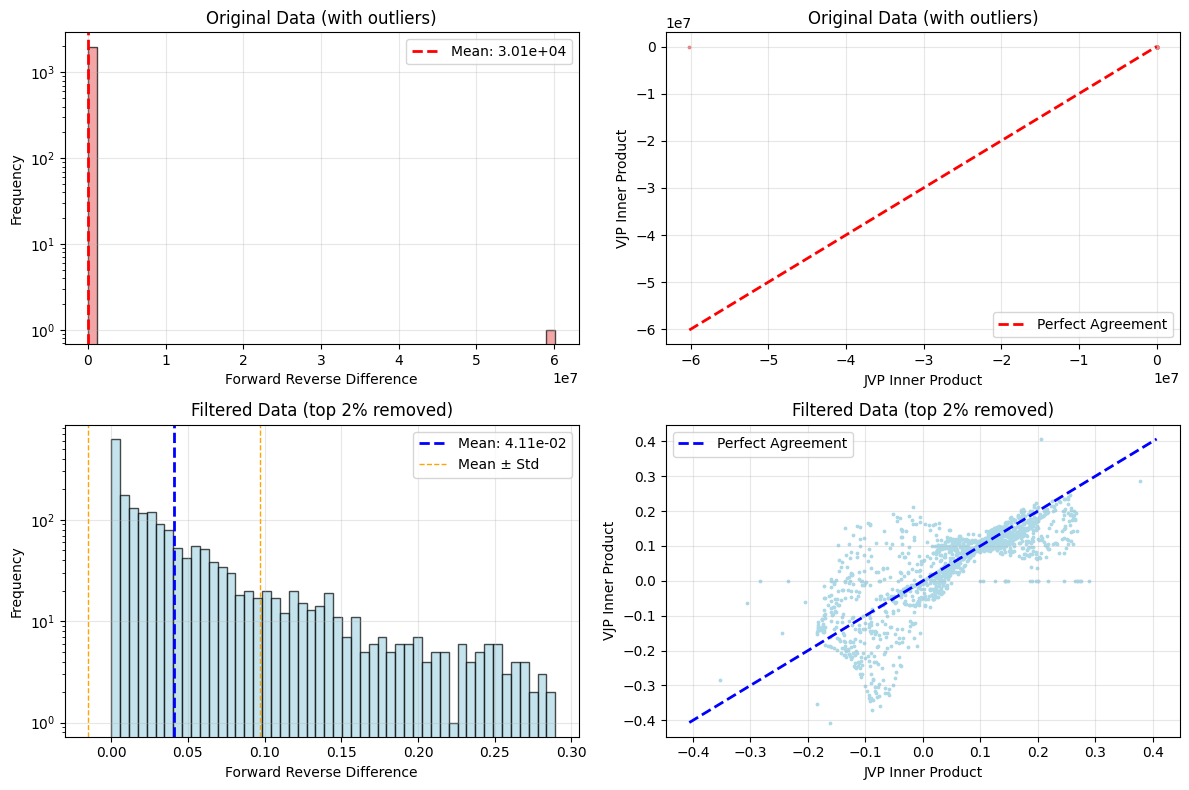

In [8]:
# Visualize gradient check results (with outlier filtering)
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 8))

# Top row: Original data
# Histogram of differences (original)
ax1.hist(
    differences_np, bins=50, alpha=0.7, edgecolor="black", color="lightcoral"
)
ax1.axvline(
    mean_difference,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_difference:.2e}",
)
ax1.set_xlabel("Forward Reverse Difference")
ax1.set_ylabel("Frequency")
ax1.set_title("Original Data (with outliers)")
ax1.set_yscale("log")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Scatter plot (original)
ax2.scatter(ip_jvps_np, ip_vjps_np, s=3, color="lightcoral")
min_val_orig = min(np.min(ip_jvps_np), np.min(ip_vjps_np))
max_val_orig = max(np.max(ip_jvps_np), np.max(ip_vjps_np))
ax2.plot(
    [min_val_orig, max_val_orig],
    [min_val_orig, max_val_orig],
    "r--",
    linewidth=2,
    label="Perfect Agreement",
)
ax2.set_xlabel("JVP Inner Product")
ax2.set_ylabel("VJP Inner Product")
ax2.set_title("Original Data (with outliers)")
ax2.legend()
ax2.grid(True, alpha=0.3)

# Bottom row: Filtered data
# Histogram of differences (filtered)
ax3.hist(
    differences_filtered,
    bins=50,
    alpha=0.7,
    edgecolor="black",
    color="lightblue",
)
ax3.axvline(
    mean_diff_filtered,
    color="blue",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_diff_filtered:.2e}",
)
ax3.axvline(
    mean_diff_filtered + std_diff_filtered,
    color="orange",
    linestyle="--",
    linewidth=1,
    label="Mean ± Std",
)
ax3.axvline(
    mean_diff_filtered - std_diff_filtered,
    color="orange",
    linestyle="--",
    linewidth=1,
)
ax3.set_xlabel("Forward Reverse Difference")
ax3.set_ylabel("Frequency")
ax3.set_title("Filtered Data (top 2% removed)")
ax3.set_yscale("log")
ax3.legend()
ax3.grid(True, alpha=0.3)

# Scatter plot (filtered)
ax4.scatter(ip_jvps_filtered, ip_vjps_filtered, s=3, color="lightblue")
min_val_filt = min(np.min(ip_jvps_filtered), np.min(ip_vjps_filtered))
max_val_filt = max(np.max(ip_jvps_filtered), np.max(ip_vjps_filtered))
ax4.plot(
    [min_val_filt, max_val_filt],
    [min_val_filt, max_val_filt],
    "b--",
    linewidth=2,
    label="Perfect Agreement",
)
ax4.set_xlabel("JVP Inner Product")
ax4.set_ylabel("VJP Inner Product")
ax4.set_title("Filtered Data (top 2% removed)")
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()

# Save as PDF
plt.savefig("clover_histograms.pdf", format="pdf", bbox_inches="tight")
plt.show()

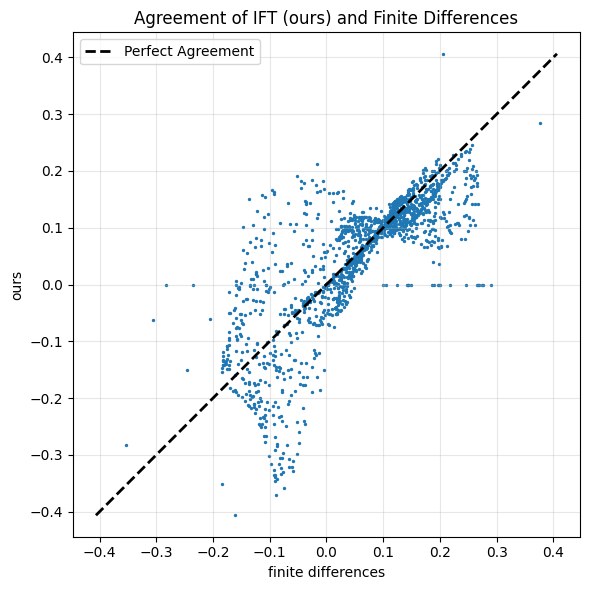

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(ip_jvps_filtered, ip_vjps_filtered, s=2)
min_val_filt = min(np.min(ip_jvps_filtered), np.min(ip_vjps_filtered))
max_val_filt = max(np.max(ip_jvps_filtered), np.max(ip_vjps_filtered))
ax.plot(
    [min_val_filt, max_val_filt],
    [min_val_filt, max_val_filt],
    "k--",
    linewidth=2,
    label="Perfect Agreement",
)
ax.set_xlabel("finite differences")
ax.set_ylabel("ours")
ax.set_title("Agreement of IFT (ours) and Finite Differences")
ax.legend()
ax.grid(True, alpha=0.3)
ax.axis("equal")


plt.tight_layout()
plt.savefig("clover_agreement.pdf", format="pdf", bbox_inches="tight")

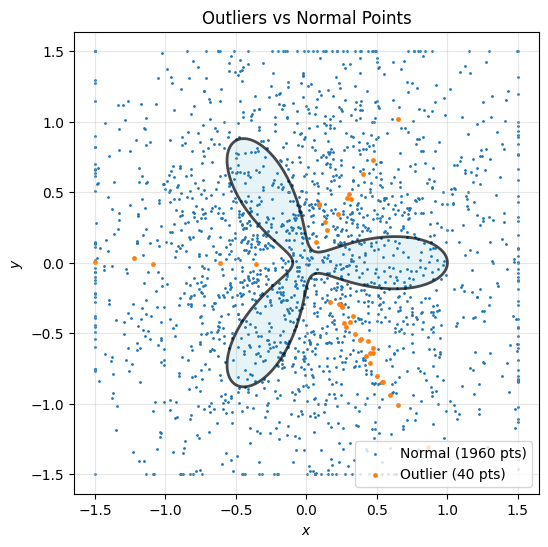

In [10]:
# Create spatial plot showing outliers vs normal points
fig, ax = plt.subplots(1, 1, figsize=(6, 6))

# Recompute constraint boundary for the plot
x_range = np.linspace(-1.2, 1.2, 200)
y_range = np.linspace(-1.2, 1.2, 200)
X_plot, Y_plot = np.meshgrid(x_range, y_range)

constraint_values_plot = (
    X_plot**4
    + 2 * X_plot**2 * Y_plot**2
    + Y_plot**4
    - X_plot**3
    + 3 * X_plot * Y_plot**2
)

# Plot constraint boundary
ax.contour(
    X_plot,
    Y_plot,
    constraint_values_plot,
    levels=[1e-3],
    colors="black",
    linewidths=2,
    alpha=0.7,
)
ax.contourf(
    X_plot,
    Y_plot,
    constraint_values_plot,
    levels=[-2, 1e-3],
    colors=["lightblue"],
    alpha=0.3,
)

# Plot normal points in blue
normal_points = x_ref_samples_jax[outlier_mask]
ax.scatter(
    normal_points[:, 0],
    normal_points[:, 1],
    c="C0",
    s=1,
    label=f"Normal ({len(normal_points)} pts)",
)

# Plot outliers in red
outlier_points = x_ref_samples_jax[~outlier_mask]
if len(outlier_points) > 0:
    ax.scatter(
        outlier_points[:, 0],
        outlier_points[:, 1],
        c="C1",
        s=6,
        label=f"Outlier ({len(outlier_points)} pts)",
    )

ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_title("Outliers vs Normal Points")
ax.legend()
ax.grid(True, alpha=0.3)
ax.axis("equal")

# Save as PDF
plt.savefig("clover_vjp_scatter.pdf", format="pdf", bbox_inches="tight")
plt.show()